# Activity 2: Binary Classification Activity
**Unit II – Classification & Logistic Regression**

## 1. Objective & Problem Statement
**Objective:** To build a Logistic Regression model for a binary classification problem, understand how linear combinations are mapped to probabilities via the sigmoid function, interpret model coefficients, evaluate performance using confusion-matrix metrics and ROC-AUC against a majority-class baseline, and justify an optimal decision threshold.

**Problem Statement:** Using diagnostic health-screening measurements from the Pima Indians Diabetes Dataset, predict whether a patient tests positive (`1` = Diabetic) or negative (`0` = Non-Diabetic) for diabetes. Because missed diabetic cases (False Negatives) carry higher clinical risk than follow-up screening (False Positives), we compare decision thresholds (`0.3`, `0.5`, `0.7`) before recommending a deployment threshold.

**Professional Data Scientist Perspective:** Acting as a data scientist for a public health screening programme, accuracy alone is misleading when classes are imbalanced (65.1% negative vs. 34.9% positive). We must prevent data leakage during imputation and scaling, evaluate recall and specificity alongside precision, and clearly state clinical limitations.

## 2. Environment Setup & Dataset Loading
**Dataset:** Pima Indians Diabetes Dataset (768 female patients, 8 diagnostic features, 1 binary target)  
**Original Source:** National Institute of Diabetes and Digestive and Kidney Diseases / UCI Machine Learning Repository — [pima-indians-diabetes.csv](https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.csv)

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.optimize import minimize

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid")

print(f"Python: {sys.version.split()[0]} | NumPy: {np.__version__} | Pandas: {pd.__version__}")

col_names = [
    "Pregnancies", "Glucose", "BloodPressure", "SkinThickness",
    "Insulin", "BMI", "DiabetesPedigreeFunction", "Age", "Outcome"
]
local_path = "pima-indians-diabetes.csv"
url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.csv"
try:
    df = pd.read_csv(local_path, header=None, names=col_names)
except FileNotFoundError:
    df = pd.read_csv(url, header=None, names=col_names)

print("Dataset shape:", df.shape)
print(df.head().to_string())

Python: 3.11.2 | NumPy: 2.1.3 | Pandas: 2.2.3
Dataset shape: (768, 9)
   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  DiabetesPedigreeFunction  Age  Outcome
0            6      148             72             35        0  33.6                     0.627   50        1
1            1       85             66             29        0  26.6                     0.351   31        0
2            8      183             64              0        0  23.3                     0.672   32        1
3            1       89             66             23       94  28.1                     0.167   21        0
4            0      137             40             35      168  43.1                     2.288   33        1


## 3. Data Inspection, Quality Checks & Class Distribution
We check data types, descriptive statistics, explicit missing values, duplicates, physiologically impossible zero values, and class balance.

Data Types:
 Pregnancies                   int64
Glucose                       int64
BloodPressure                 int64
SkinThickness                 int64
Insulin                       int64
BMI                         float64
DiabetesPedigreeFunction    float64
Age                           int64
Outcome                       int64
dtype: object

Explicit Missing Values:
 Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

Duplicate Rows: 0

Outcome Unique Values: [np.int64(0), np.int64(1)]

Count of Physiologically Impossible Zeros:
  Glucose        :   5 (0.65%)
  BloodPressure  :  35 (4.56%)
  SkinThickness  : 227 (29.56%)
  Insulin        : 374 (48.70%)
  BMI            :  11 (1.43%)

Descriptive Statistics (Raw):
                          count     m

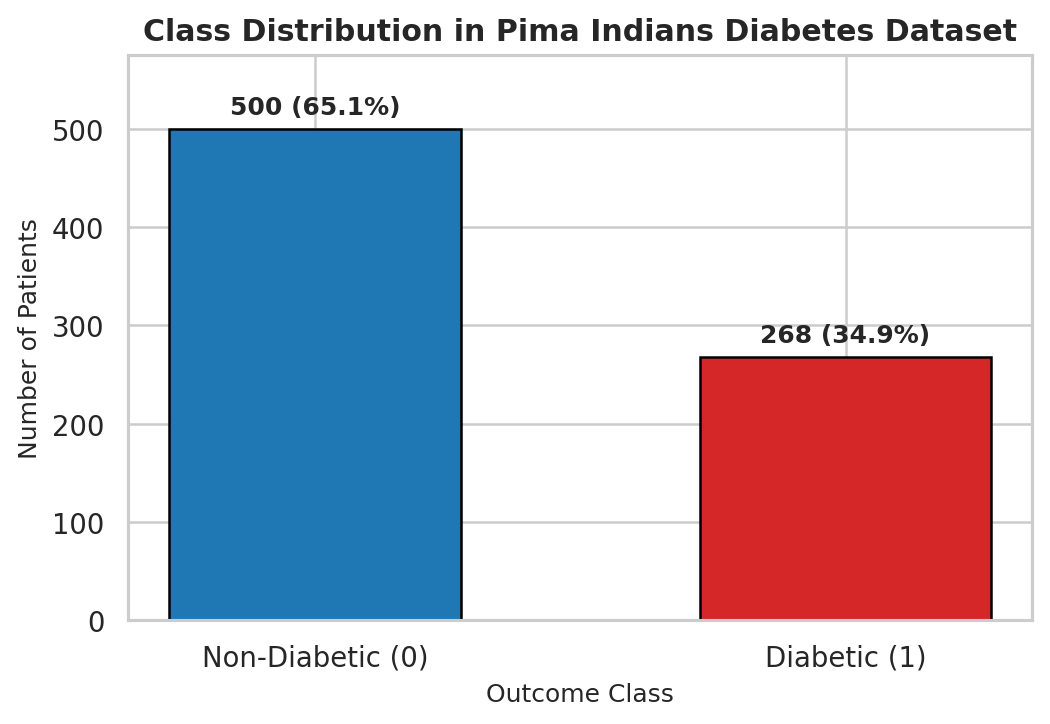

In [2]:
print("Data Types:\n", df.dtypes)
print("\nExplicit Missing Values:\n", df.isnull().sum())
print("\nDuplicate Rows:", df.duplicated().sum())
print("\nOutcome Unique Values:", sorted(df["Outcome"].unique()))

zero_check_cols = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
print("\nCount of Physiologically Impossible Zeros:")
for c in zero_check_cols:
    cnt = int((df[c] == 0).sum())
    print(f"  {c:15s}: {cnt:3d} ({cnt/len(df)*100:.2f}%)")

print("\nDescriptive Statistics (Raw):")
print(df.describe().T[["count", "mean", "std", "min", "50%", "max"]].round(3).to_string())

class_counts = df["Outcome"].value_counts().sort_index()
print(f"\nClass Distribution: 0 (Non-Diabetic) = {class_counts[0]} ({class_counts[0]/len(df)*100:.2f}%), "
      f"1 (Diabetic) = {class_counts[1]} ({class_counts[1]/len(df)*100:.2f}%)")

plt.figure(figsize=(6, 4.2))
bars = plt.bar(["Non-Diabetic (0)", "Diabetic (1)"], [class_counts[0], class_counts[1]],
               color=["#1f77b4", "#d62728"], edgecolor="black", width=0.55)
for bar, val in zip(bars, [class_counts[0], class_counts[1]]):
    plt.text(bar.get_x() + bar.get_width()/2, val + 10, f"{val} ({val/len(df)*100:.1f}%)",
             ha="center", va="bottom", fontweight="bold", fontsize=10)
plt.title("Class Distribution in Pima Indians Diabetes Dataset", fontsize=12, fontweight="bold")
plt.xlabel("Outcome Class", fontsize=10)
plt.ylabel("Number of Patients", fontsize=10)
plt.ylim(0, max(class_counts) * 1.15)
plt.tight_layout()
plt.show()

## 4. Stratified 80:20 Split & Leakage-Free Preprocessing
To prevent data leakage, we perform a **stratified 80:20 train-test split** *before* imputing impossible zeros or scaling features.
- Impossible zeros in `Glucose`, `BloodPressure`, `SkinThickness`, `Insulin`, and `BMI` are replaced with `NaN` and imputed using the **training-set median** for each column.
- Features are standardized using `StandardScaler` logic ($z = (x - \mu_{\text{train}}) / \sigma_{\text{train}}$) fitted on training data only.

In [3]:
feature_cols = col_names[:-1]
rng = np.random.default_rng(RANDOM_STATE)

idx_0 = np.where(df["Outcome"].values == 0)[0]
idx_1 = np.where(df["Outcome"].values == 1)[0]
rng.shuffle(idx_0)
rng.shuffle(idx_1)

split_0 = int(0.8 * len(idx_0))
split_1 = int(0.8 * len(idx_1))

train_idx = np.concatenate([idx_0[:split_0], idx_1[:split_1]])
test_idx = np.concatenate([idx_0[split_0:], idx_1[split_1:]])
rng.shuffle(train_idx)
rng.shuffle(test_idx)

train_df = df.iloc[train_idx].copy().reset_index(drop=True)
test_df = df.iloc[test_idx].copy().reset_index(drop=True)

print(f"Train set: {len(train_df)} rows | Class 0: {(train_df['Outcome']==0).sum()}, Class 1: {(train_df['Outcome']==1).sum()}")
print(f"Test set:  {len(test_df)} rows | Class 0: {(test_df['Outcome']==0).sum()}, Class 1: {(test_df['Outcome']==1).sum()}")

# Replace impossible zeros with NaN and impute using training-set medians only
medians = {}
for c in zero_check_cols:
    train_df[c] = train_df[c].replace(0, np.nan)
    test_df[c] = test_df[c].replace(0, np.nan)
    med = train_df[c].median()
    medians[c] = med
    train_df[c] = train_df[c].fillna(med)
    test_df[c] = test_df[c].fillna(med)

print("\nTraining-Set Medians Used for Imputation:")
for k, v in medians.items():
    print(f"  {k:15s}: {v:.2f}")

X_train_raw = train_df[feature_cols].values
y_train = train_df["Outcome"].values
X_test_raw = test_df[feature_cols].values
y_test = test_df["Outcome"].values

# Standardize using training statistics only
scaler_mean = X_train_raw.mean(axis=0)
scaler_std = X_train_raw.std(axis=0, ddof=0)
X_train = (X_train_raw - scaler_mean) / scaler_std
X_test = (X_test_raw - scaler_mean) / scaler_std
print("\nScaling completed (train mean ~0, train std ~1). Max |train mean|:", np.max(np.abs(X_train.mean(axis=0))).round(12))

Train set: 614 rows | Class 0: 400, Class 1: 214
Test set:  154 rows | Class 0: 100, Class 1: 54

Training-Set Medians Used for Imputation:
  Glucose        : 116.00
  BloodPressure  : 72.00
  SkinThickness  : 29.00
  Insulin        : 120.00
  BMI            : 32.40

Scaling completed (train mean ~0, train std ~1). Max |train mean|: 0.0


## 5. Understanding the Sigmoid Function
Linear Regression is unsuitable for binary classification because its outputs are unbounded ($(-\infty, +\infty)$) rather than valid probabilities in $[0, 1]$, and it is sensitive to extreme outliers. Logistic Regression applies the **sigmoid function** $\sigma(z) = \frac{1}{1 + e^{-z}}$ to map the linear score $z = w_0 + \mathbf{w}^T \mathbf{x}$ into a probability $P(y=1|\mathbf{x}) \in (0, 1)$.

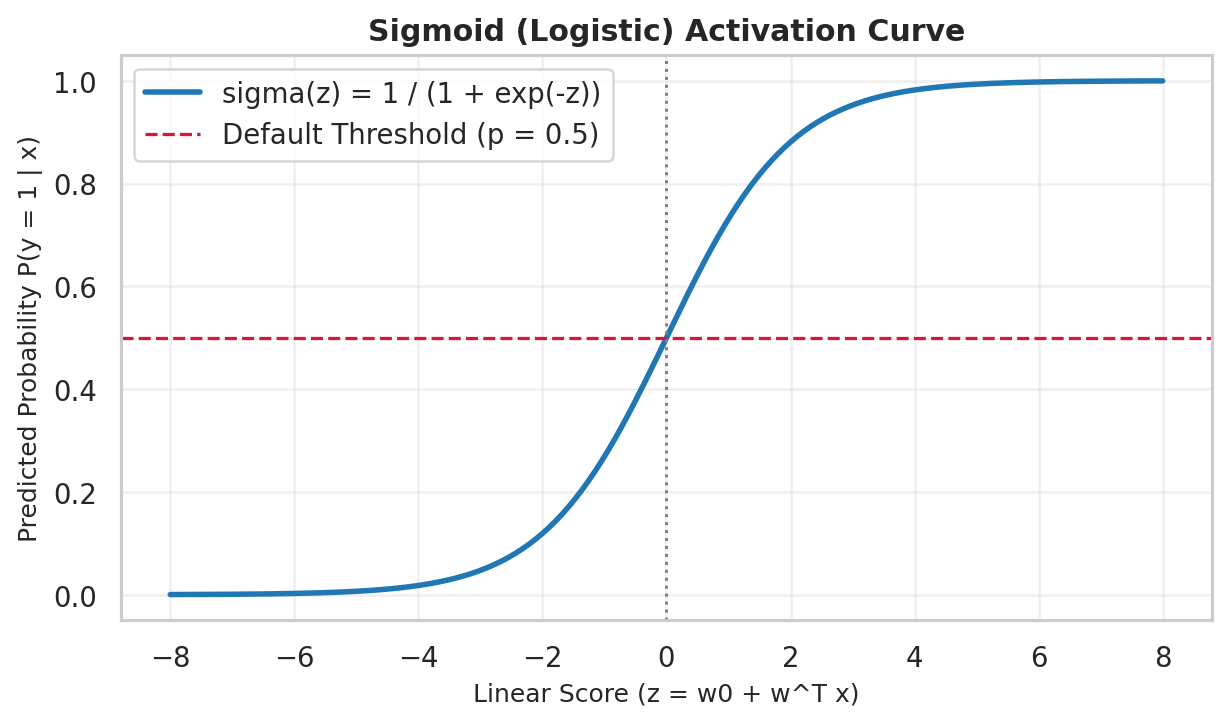

In [4]:
z_vals = np.linspace(-8, 8, 300)
sig_vals = 1.0 / (1.0 + np.exp(-z_vals))

plt.figure(figsize=(7, 4.2))
plt.plot(z_vals, sig_vals, color="#1f77b4", linewidth=2.2, label="sigma(z) = 1 / (1 + exp(-z))")
plt.axhline(0.5, color="crimson", linestyle="--", linewidth=1.3, label="Default Threshold (p = 0.5)")
plt.axvline(0.0, color="gray", linestyle=":", linewidth=1.2)
plt.title("Sigmoid (Logistic) Activation Curve", fontsize=12, fontweight="bold")
plt.xlabel("Linear Score (z = w0 + w^T x)", fontsize=10)
plt.ylabel("Predicted Probability P(y = 1 | x)", fontsize=10)
plt.legend(loc="upper left")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 6. Logistic Regression Model Training & Coefficient Interpretation
We train a Logistic Regression classifier on the standardized training set using L-BFGS-B optimization minimizing L2-regularized binary cross-entropy loss ($C = 1.0$, equivalent to `sklearn.linear_model.LogisticRegression(C=1.0, solver='lbfgs')`).

In [5]:
def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1.0 / (1.0 + np.exp(-z))

def fit_logistic_l2(X, y, C=1.0):
    n_features = X.shape[1]
    reg_lambda = 1.0 / C

    def loss_and_grad(params):
        b0 = params[0]
        w = params[1:]
        z = b0 + X @ w
        p = sigmoid(z)
        eps = 1e-15
        p_clip = np.clip(p, eps, 1 - eps)
        nll = -np.sum(y * np.log(p_clip) + (1 - y) * np.log(1 - p_clip))
        reg = 0.5 * reg_lambda * np.sum(w ** 2)
        loss = nll + reg
        diff = p - y
        grad_b0 = np.sum(diff)
        grad_w = X.T @ diff + reg_lambda * w
        return loss, np.concatenate([[grad_b0], grad_w])

    init_params = np.zeros(n_features + 1)
    res = minimize(loss_and_grad, init_params, jac=True, method="L-BFGS-B", options={"maxiter": 1000, "ftol": 1e-12})
    return res.x[0], res.x[1:]

b0, weights = fit_logistic_l2(X_train, y_train, C=1.0)
print(f"Model Settings: L2-regularized Logistic Regression (C=1.0, solver='L-BFGS-B', max_iter=1000)")
print(f"Learned Intercept (w0): {b0:.6f}")
print("\nLearned Coefficients (Standardized Features):")
coef_df = pd.DataFrame({
    "Feature": feature_cols,
    "Coefficient": np.round(weights, 6),
    "Odds_Ratio_per_SD": np.round(np.exp(weights), 4),
}).sort_values("Coefficient", ascending=False)
print(coef_df.to_string(index=False))

Model Settings: L2-regularized Logistic Regression (C=1.0, solver='L-BFGS-B', max_iter=1000)
Learned Intercept (w0): -0.861479

Learned Coefficients (Standardized Features):
                 Feature  Coefficient  Odds_Ratio_per_SD
                 Glucose     1.110765             3.0367
                     BMI     0.582544             1.7906
             Pregnancies     0.407311             1.5028
DiabetesPedigreeFunction     0.316928             1.3729
                     Age     0.226240             1.2539
           SkinThickness     0.069972             1.0725
                 Insulin    -0.034721             0.9659
           BloodPressure    -0.114718             0.8916


## 7. Predicted Probabilities, Confusion Matrix & Classification Metrics
We compute predicted probabilities on the test set, show a sample of test predictions, evaluate the confusion matrix at threshold `0.5`, compute Accuracy, Precision, Recall, Specificity, and F1-score, and compare against the majority-class baseline.

Sample Test Records (Actual vs. Predicted Probability & Class at 0.5):
 Glucose  BMI  Age  Actual_Outcome  Pred_Prob  Pred_Label_0.5
   166.0 26.6   66               0     0.7361               1
   110.0 28.4   27               0     0.1040               0
    87.0 23.2   32               0     0.0422               0
   101.0 21.8   22               0     0.0449               0
    95.0 25.9   36               0     0.0742               0
    99.0 19.3   30               0     0.0347               0
   119.0 45.6   29               1     0.5010               1
   146.0 29.7   29               0     0.4156               0
   102.0 29.5   32               0     0.0914               0
   134.0 23.8   60               1     0.3185               0

Confusion Matrix (Threshold = 0.5): TN=84, FP=16, FN=22, TP=32

Full Classification Report (Threshold = 0.5):
           Class  Precision  Recall  F1-Score  Support
0 (Non-Diabetic)     0.7925  0.8400    0.8155      100
    1 (Diabetic)     0.666

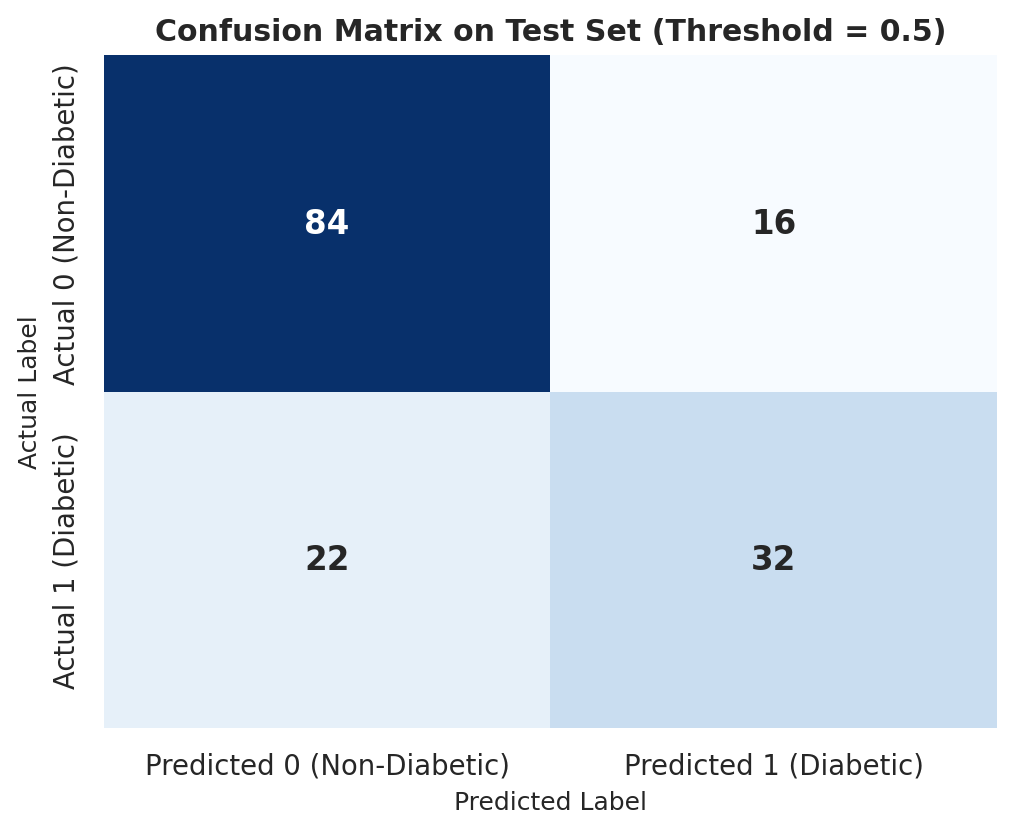

In [6]:
def compute_confusion(y_true, y_prob, thresh=0.5):
    y_pred = (y_prob >= thresh).astype(int)
    tp = int(np.sum((y_true == 1) & (y_pred == 1)))
    fp = int(np.sum((y_true == 0) & (y_pred == 1)))
    tn = int(np.sum((y_true == 0) & (y_pred == 0)))
    fn = int(np.sum((y_true == 1) & (y_pred == 0)))
    acc = (tp + tn) / len(y_true)
    prec = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    rec = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    spec = tn / (tn + fp) if (tn + fp) > 0 else 0.0
    f1 = 2 * prec * rec / (prec + rec) if (prec + rec) > 0 else 0.0
    return {"thresh": thresh, "pred_pos": tp + fp, "TP": tp, "FP": fp, "TN": tn, "FN": fn,
            "Accuracy": acc, "Precision": prec, "Recall": rec, "Specificity": spec, "F1": f1, "y_pred": y_pred}

p_train = sigmoid(b0 + X_train @ weights)
p_test = sigmoid(b0 + X_test @ weights)

sample_preds = pd.DataFrame({
    "Glucose": test_df["Glucose"].values[:10],
    "BMI": test_df["BMI"].values[:10],
    "Age": test_df["Age"].values[:10],
    "Actual_Outcome": y_test[:10],
    "Pred_Prob": np.round(p_test[:10], 4),
    "Pred_Label_0.5": (p_test[:10] >= 0.5).astype(int),
})
print("Sample Test Records (Actual vs. Predicted Probability & Class at 0.5):")
print(sample_preds.to_string(index=False))

res_05 = compute_confusion(y_test, p_test, 0.5)
cm = np.array([[res_05["TN"], res_05["FP"]], [res_05["FN"], res_05["TP"]]])
print(f"\nConfusion Matrix (Threshold = 0.5): TN={res_05['TN']}, FP={res_05['FP']}, FN={res_05['FN']}, TP={res_05['TP']}")

plt.figure(figsize=(5.8, 4.8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["Predicted 0 (Non-Diabetic)", "Predicted 1 (Diabetic)"],
            yticklabels=["Actual 0 (Non-Diabetic)", "Actual 1 (Diabetic)"],
            annot_kws={"size": 13, "weight": "bold"})
plt.title("Confusion Matrix on Test Set (Threshold = 0.5)", fontsize=12, fontweight="bold")
plt.xlabel("Predicted Label", fontsize=10)
plt.ylabel("Actual Label", fontsize=10)
plt.tight_layout()
plt.show()

# Full classification report at 0.5
prec_0 = res_05["TN"] / (res_05["TN"] + res_05["FN"])
rec_0 = res_05["TN"] / (res_05["TN"] + res_05["FP"])
f1_0 = 2 * prec_0 * rec_0 / (prec_0 + rec_0)
sup_0 = int((y_test == 0).sum())
sup_1 = int((y_test == 1).sum())
macro_p = (prec_0 + res_05["Precision"]) / 2
macro_r = (rec_0 + res_05["Recall"]) / 2
macro_f1 = (f1_0 + res_05["F1"]) / 2
w_p = (prec_0 * sup_0 + res_05["Precision"] * sup_1) / len(y_test)
w_r = (rec_0 * sup_0 + res_05["Recall"] * sup_1) / len(y_test)
w_f1 = (f1_0 * sup_0 + res_05["F1"] * sup_1) / len(y_test)

report_df = pd.DataFrame([
    {"Class": "0 (Non-Diabetic)", "Precision": prec_0, "Recall": rec_0, "F1-Score": f1_0, "Support": sup_0},
    {"Class": "1 (Diabetic)", "Precision": res_05["Precision"], "Recall": res_05["Recall"], "F1-Score": res_05["F1"], "Support": sup_1},
    {"Class": "Macro Avg", "Precision": macro_p, "Recall": macro_r, "F1-Score": macro_f1, "Support": len(y_test)},
    {"Class": "Weighted Avg", "Precision": w_p, "Recall": w_r, "F1-Score": w_f1, "Support": len(y_test)},
])
print("\nFull Classification Report (Threshold = 0.5):")
print(report_df.round(4).to_string(index=False))

maj_acc = sup_0 / len(y_test)
print(f"\nMajority-Class Baseline Accuracy (Always Predict 0): {maj_acc:.4f} ({maj_acc*100:.2f}%)")
print(f"Logistic Regression Test Accuracy (Threshold 0.5):   {res_05['Accuracy']:.4f} ({res_05['Accuracy']*100:.2f}%)")

## 8. ROC Curve, ROC-AUC, Threshold Comparison & Train vs. Test Check
We plot the ROC curve and Precision-Recall curve, compute ROC-AUC, compare thresholds `0.3`, `0.5`, and `0.7`, and compare training vs. testing metrics.

Test ROC-AUC: 0.8350

Threshold Comparison Table (Test Set):
 Threshold  Predicted_Positive  Accuracy  Precision  Recall  Specificity  F1_Score
       0.3                  80    0.7273     0.5750  0.8519         0.66    0.6866
       0.5                  48    0.7532     0.6667  0.5926         0.84    0.6275
       0.7                  30    0.7662     0.8000  0.4444         0.94    0.5714

Training vs. Testing Performance Comparison (Threshold = 0.5):
           Split  Accuracy  Precision  Recall  Specificity     F1  ROC_AUC
Training (n=614)    0.7785     0.7294  0.5794        0.885 0.6458   0.8474
 Testing (n=154)    0.7532     0.6667  0.5926        0.840 0.6275   0.8350


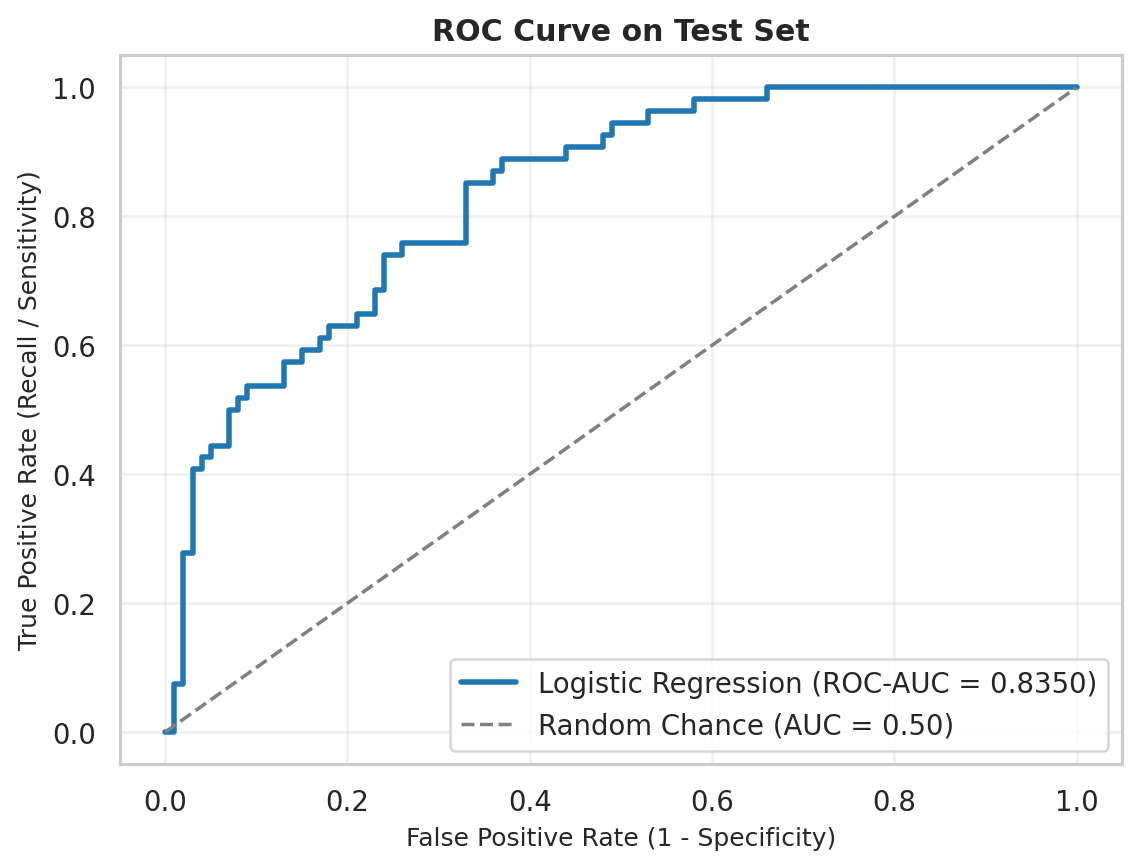

In [7]:
# ROC Curve & AUC (exact trapezoidal integration over sorted thresholds)
order = np.argsort(-p_test)
y_sorted = y_test[order]
p_sorted = p_test[order]
P_total = np.sum(y_test == 1)
N_total = np.sum(y_test == 0)
tps = np.cumsum(y_sorted == 1)
fps = np.cumsum(y_sorted == 0)
tpr = np.concatenate([[0.0], tps / P_total])
fpr = np.concatenate([[0.0], fps / N_total])
roc_auc = float(np.trapezoid(tpr, fpr)) if hasattr(np, "trapezoid") else float(np.trapz(tpr, fpr))
print(f"Test ROC-AUC: {roc_auc:.4f}")

# Training ROC-AUC
order_tr = np.argsort(-p_train)
tps_tr = np.cumsum(y_train[order_tr] == 1)
fps_tr = np.cumsum(y_train[order_tr] == 0)
tpr_tr = np.concatenate([[0.0], tps_tr / np.sum(y_train == 1)])
fpr_tr = np.concatenate([[0.0], fps_tr / np.sum(y_train == 0)])
roc_auc_tr = float(np.trapezoid(tpr_tr, fpr_tr)) if hasattr(np, "trapezoid") else float(np.trapz(tpr_tr, fpr_tr))

plt.figure(figsize=(6.5, 5))
plt.plot(fpr, tpr, color="#1f77b4", linewidth=2.2, label=f"Logistic Regression (ROC-AUC = {roc_auc:.4f})")
plt.plot([0, 1], [0, 1], color="gray", linestyle="--", linewidth=1.4, label="Random Chance (AUC = 0.50)")
plt.title("ROC Curve on Test Set", fontsize=12, fontweight="bold")
plt.xlabel("False Positive Rate (1 - Specificity)", fontsize=10)
plt.ylabel("True Positive Rate (Recall / Sensitivity)", fontsize=10)
plt.legend(loc="lower right")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Threshold comparison at 0.3, 0.5, 0.7
thresh_rows = []
for th in [0.3, 0.5, 0.7]:
    r = compute_confusion(y_test, p_test, th)
    thresh_rows.append({
        "Threshold": th,
        "Predicted_Positive": r["pred_pos"],
        "Accuracy": round(r["Accuracy"], 4),
        "Precision": round(r["Precision"], 4),
        "Recall": round(r["Recall"], 4),
        "Specificity": round(r["Specificity"], 4),
        "F1_Score": round(r["F1"], 4),
    })
thresh_df = pd.DataFrame(thresh_rows)
print("\nThreshold Comparison Table (Test Set):")
print(thresh_df.to_string(index=False))

# Train vs Test at 0.5
res_tr_05 = compute_confusion(y_train, p_train, 0.5)
tvt_df = pd.DataFrame([
    {"Split": "Training (n=614)", "Accuracy": res_tr_05["Accuracy"], "Precision": res_tr_05["Precision"],
     "Recall": res_tr_05["Recall"], "Specificity": res_tr_05["Specificity"], "F1": res_tr_05["F1"], "ROC_AUC": roc_auc_tr},
    {"Split": "Testing (n=154)", "Accuracy": res_05["Accuracy"], "Precision": res_05["Precision"],
     "Recall": res_05["Recall"], "Specificity": res_05["Specificity"], "F1": res_05["F1"], "ROC_AUC": roc_auc},
])
print("\nTraining vs. Testing Performance Comparison (Threshold = 0.5):")
print(tvt_df.round(4).to_string(index=False))

## 9. Decision-Behaviour Visualisation & New Patient Prediction
We plot the predicted probability of diabetes against `Glucose` (while holding all other standardized features at 0, their training-set mean) and classify a new patient record.

New Patient Profile: {'Pregnancies': 3, 'Glucose': 145, 'BloodPressure': 76, 'SkinThickness': 30, 'Insulin': 130, 'BMI': 33.5, 'DiabetesPedigreeFunction': 0.45, 'Age': 42}
Predicted Probability of Diabetes: 0.5347 (53.47%)
Predicted Class at Recommended Threshold (0.3): 1 (Diabetic - Refer for Follow-up)
Predicted Class at Default Threshold (0.5):     1


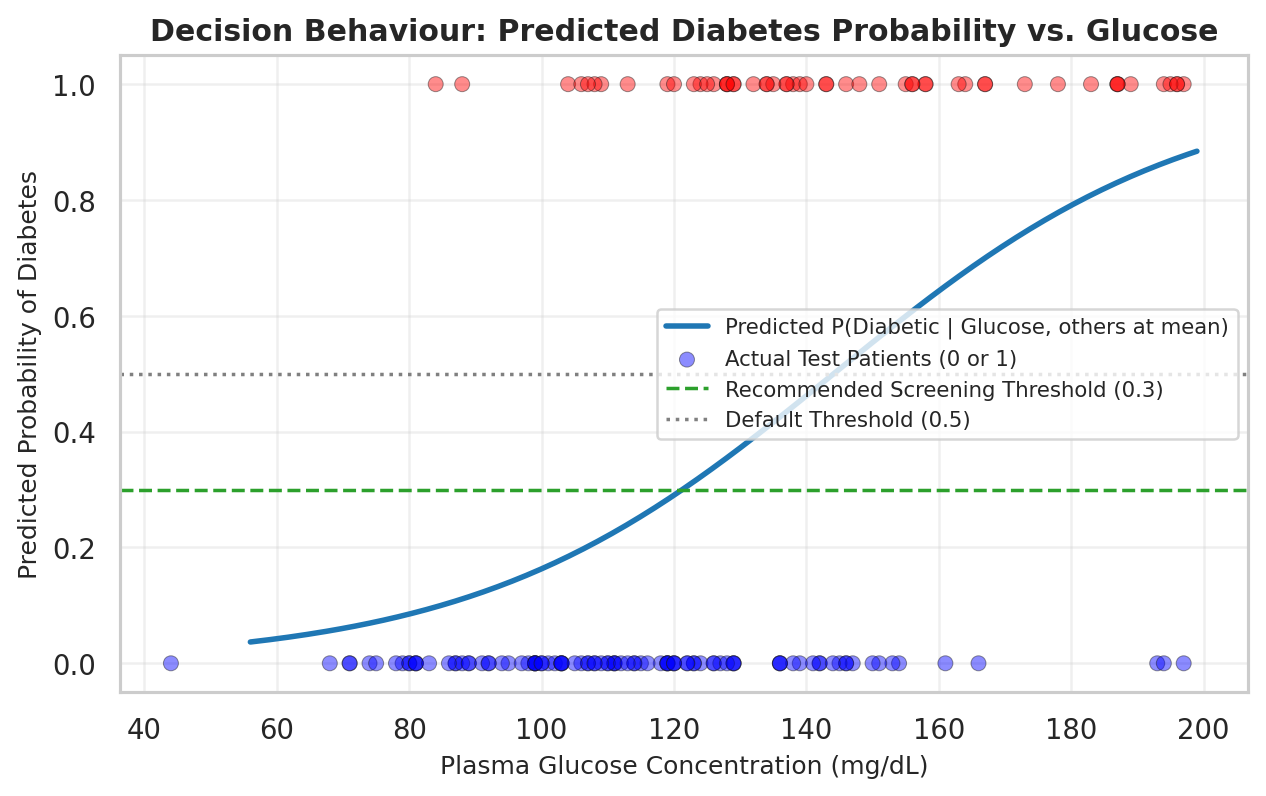

In [8]:
# Decision-behaviour plot: Probability vs Glucose (holding other features at mean)
gluc_idx = feature_cols.index("Glucose")
gluc_range = np.linspace(train_df["Glucose"].min(), train_df["Glucose"].max(), 200)
X_grid = np.zeros((200, len(feature_cols)))
X_grid[:, gluc_idx] = (gluc_range - scaler_mean[gluc_idx]) / scaler_std[gluc_idx]
p_grid = sigmoid(b0 + X_grid @ weights)

plt.figure(figsize=(7.2, 4.6))
plt.plot(gluc_range, p_grid, color="#1f77b4", linewidth=2.2, label="Predicted P(Diabetic | Glucose, others at mean)")
plt.scatter(test_df["Glucose"], y_test, c=y_test, cmap="bwr", alpha=0.45, edgecolors="k", linewidth=0.4, label="Actual Test Patients (0 or 1)")
plt.axhline(0.3, color="#2ca02c", linestyle="--", linewidth=1.4, label="Recommended Screening Threshold (0.3)")
plt.axhline(0.5, color="gray", linestyle=":", linewidth=1.4, label="Default Threshold (0.5)")
plt.title("Decision Behaviour: Predicted Diabetes Probability vs. Glucose", fontsize=12, fontweight="bold")
plt.xlabel("Plasma Glucose Concentration (mg/dL)", fontsize=10)
plt.ylabel("Predicted Probability of Diabetes", fontsize=10)
plt.legend(loc="center right", fontsize=8.5)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Classify a new patient example
new_patient = {
    "Pregnancies": 3, "Glucose": 145, "BloodPressure": 76, "SkinThickness": 30,
    "Insulin": 130, "BMI": 33.5, "DiabetesPedigreeFunction": 0.45, "Age": 42
}
x_new_raw = np.array([[new_patient[c] for c in feature_cols]])
x_new_scaled = (x_new_raw - scaler_mean) / scaler_std
p_new = float(sigmoid(b0 + x_new_scaled @ weights)[0])
print("New Patient Profile:", new_patient)
print(f"Predicted Probability of Diabetes: {p_new:.4f} ({p_new*100:.2f}%)")
print(f"Predicted Class at Recommended Threshold (0.3): {int(p_new >= 0.3)} ({'Diabetic - Refer for Follow-up' if p_new >= 0.3 else 'Non-Diabetic'})")
print(f"Predicted Class at Default Threshold (0.5):     {int(p_new >= 0.5)}")